For this kaggle competition, I will try to implement ResNeXt to classify images. ResNeXt is an architecture for neural network in this paper aggregated Residual Transformations for Deep Neural Networks. https://arxiv.org/abs/1611.05431.
@article{Xie2016,
  title={Aggregated Residual Transformations for Deep Neural Networks},
  author={Saining Xie and Ross Girshick and Piotr Dollár and Zhuowen Tu and Kaiming He},
  journal={arXiv preprint arXiv:1611.05431},
  year={2016}
}
https://github.com/facebookresearch/ResNeXt used for coding inspiration
Main motivation behind implementing this was that I saw on instagram short about resNeXt which I found to be interesting and wanted to try implementing it myself.


In [12]:
from __future__ import annotations

import os
from typing import Any

os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')

import copy
import random
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import ConcatDataset, DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 2026
# On Colab the archives are uploaded to /content; locally they live in the repo's data/ folder.
ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd() / 'data'
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset_v2.zip'
# Colab: unzipped straight into ROOT/FIT5215_Dataset. Local: extracted under ROOT/Animals_Dataset_v2/.
TRAIN_DIR = next(
    (
        candidate
        for candidate in (
            ROOT / 'FIT5215_Dataset',
            ROOT / 'Animals_Dataset_v2' / 'FIT5215_Dataset',
        )
        if candidate.is_dir()
    ),
    ROOT / 'FIT5215_Dataset',
)
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working directory:', ROOT)
print('Training data:', TRAIN_DIR)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type != 'cuda':
    print('Warning: training will be much slower without a GPU runtime.')

Working directory: C:\Users\nguyen\Documents\GitHub\Deep-Learning\data
Training data: C:\Users\nguyen\Documents\GitHub\Deep-Learning\data\Animals_Dataset_v2\FIT5215_Dataset
PyTorch: 2.14.0+cu132
Device: cuda


In [13]:
EXPECTED_TEST_IMAGES = 11_681

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), (
        'Upload test_set.zip to the Colab Files pane before continuing.'
    )
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), (
    'The ZIP must contain a top-level folder named test_set.'
)
assert TEST_DIR.is_dir(), (
    'The test_set folder must contain the test_dataset image folder.'
)
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), (
    'The test_set folder must contain my_solution.csv.'
)
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


In [14]:
EXPECTED_CLASS_NAMES = [
    'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
    'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
    'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
    'spiders', 'vases',
]
CLASS_NAME_CORRECTIONS = {'butterfiles': 'butterflies'}
MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)
VALIDATION_FRACTION = 0.15

train_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
evaluation_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

index_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = [
    CLASS_NAME_CORRECTIONS.get(name, name) for name in index_dataset.classes
]
if class_names != EXPECTED_CLASS_NAMES:
    raise RuntimeError(f'Unexpected training class order: {class_names}')
targets = np.asarray(index_dataset.targets, dtype=np.int64)
rng = np.random.default_rng(SEED)
train_indices = []
validation_indices = []
for class_index in range(len(class_names)):
    class_indices = np.flatnonzero(targets == class_index)
    rng.shuffle(class_indices)
    validation_count = max(1, int(round(len(class_indices) * VALIDATION_FRACTION)))
    validation_indices.extend(class_indices[:validation_count].tolist())
    train_indices.extend(class_indices[validation_count:].tolist())
train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

training_augmented = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
training_evaluation = datasets.ImageFolder(TRAIN_DIR, transform=evaluation_transform)
train_dataset = Subset(training_augmented, train_indices)
train_evaluation_dataset = Subset(training_evaluation, train_indices)
validation_dataset = Subset(training_evaluation, validation_indices)

class KaggleTestDataset(Dataset):
    def __init__(self, paths: list[Path], transform):
        self.paths = paths
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int):
        path = self.paths[index]
        test_id = int(path.name.split('_', 1)[0])
        with Image.open(path) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, test_id

test_dataset = KaggleTestDataset(test_paths, evaluation_transform)
print('Classes:', class_names)

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']


In [15]:
BATCH_SIZE = 64
NUM_WORKERS = 0 if os.name == 'nt' else min(2, os.cpu_count() or 1)
pin_memory = device.type == 'cuda'
loader_generator = torch.Generator().manual_seed(SEED)

def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=loader_generator, worker_init_fn=seed_worker,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
train_evaluation_loader = DataLoader(
    train_evaluation_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
print(f'Train: {len(train_dataset):,}')
print(f'Validation: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')
print(f'DataLoader workers: {NUM_WORKERS}')

Train: 8,047
Validation: 1,419
Test: 11,681
DataLoader workers: 0


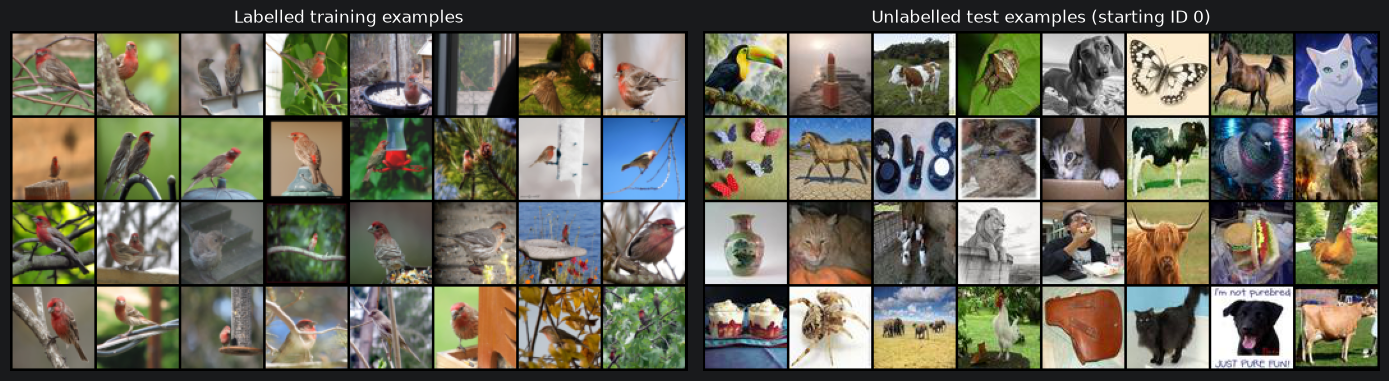

Example training label: birds


In [16]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

In [17]:

'''
class ResNextBlock(nn.Module):

    def __init__(self, in_channel: int, out_channel: int, cardinality = 16, stride = 2):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channel, in_channel, kernel_size=1, stride=1, padding='same', bias=False)
        self.bn1 = nn.BatchNorm2d(in_channel)
        # group conv layer equivalent to parrallel figure 3 part c
        self.conv2 = nn.Conv2d(in_channel, in_channel, kernel_size=3, stride= stride,groups= cardinality ,padding='same', bias=False)
        self.bn2 = nn.BatchNorm2d(in_channel)
        # convert to next output channel
        self.conv3 = nn.Conv2d(in_channel, out_channel, kernel_size=1, stride=1, padding='same', bias=False)
        self.bn3 = nn.BatchNorm2d(out_channel)
        self.relu = nn.ReLU(inplace=True)

        # dont need if else since resNext implement require different in out channel at all stage
        self.shortcut = nn.Sequential(nn.Conv2d(in_channels=in_channel, out_channels=out_channel, kernel_size=1, stride=stride, bias=False), nn.BatchNorm2d(out_channel),)


    def foward(self,x ):
        out= self.conv1(x)
        out= self.bn1(out)
        out= self.relu(out)
        out= self.conv2(out)
        out= self.bn2(out)
        out= self.relu(out)
        out= self.conv3(out)
        out= self.bn3(out)
        out= self.relu(out)
        out= out + self.shortcut(x)
        return out


class MyResNext(nn.Module):

    def __init__(self, num_classes=8, cardinality=16, width = 4, num_block_layer = (2,3,2)):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        self.layer1 = self._make_layer(Bottleneck2x, 64,  layers[0], stride=1)  # 16x16, out 128
        self.layer2 = self._make_layer(Bottleneck2x, 128, layers[1], stride=2)  # 8x8,   out 256
        self.layer3 = self._make_layer(Bottleneck2x, 256, layers[2], stride=2)  # 4x4,   out 512
'''
from torchvision.models.resnet import ResNet, Bottleneck

class Bottleneck2x(Bottleneck):
    expansion = 2


def MyResNext(num_classes=8):
    # layer4 gets 1 block only because ResNet always builds four stages;
    # it is replaced with Identity below.
    model = ResNet(Bottleneck2x, [1, 2, 1, 1], num_classes=num_classes,
                   groups=16, width_per_group=4)

    # Stem: replace 7x7 stride-2 conv with 3x3 stride-2 (max pool is kept)
    model.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3,
                            stride=2, padding=1, bias=False)
    nn.init.kaiming_normal_(model.conv1.weight, mode="fan_out", nonlinearity="relu")

    # Drop the fourth stage; layer3 outputs 256 * 2 = 512 channels
    model.layer4 = nn.Identity()
    model.fc = nn.Linear(in_features=512, out_features=num_classes)

    return model


model = MyResNext(num_classes=len(class_names)).to(device)
trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(model)
print(f'Trainable parameters: {trainable_parameters:,}')



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck2x(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
   

In [ ]:

def rand_bbox(H, W, lam):
    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)           # centre of the box, uniform over the image
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    return y1, y2, x1, x2

def cutmix_data(X, y, alpha=1.0):
    """Returns the cut-and-pasted inputs, the two label vectors and the adjusted lam."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(X.size(0), device=X.device)
    H, W = X.size(2), X.size(3)
    y1, y2, x1, x2 = rand_bbox(H, W, lam)
    X_cut = X.clone()
    X_cut[:, :, y1:y2, x1:x2] = X[index, :, y1:y2, x1:x2]        # paste the patch of image B into image A
    lam = 1 - ((y2 - y1) * (x2 - x1) / (H * W))                    # adjust lam to the exact area after clipping
    return X_cut, y, y[index], lam

def cutmix_batch_loss(model, X, y, alpha=1.0):
    X_cut, y_a, y_b, lam = cutmix_data(X, y, alpha)
    logits = model(X_cut)
    return lam * loss_fn(logits, y_a) + (1 - lam) * loss_fn(logits, y_b)


In [ ]:
# Expanded training set: the originals, one CutMix image per original, and a
# photometrically distorted copy of both. Copies are kept in RAM as uint8 and
# normalised on access, so the three parts together cost about 400 MB.
CUTMIX_ALPHA = 1.0
GAUSSIAN_NOISE_STD = 0.08        # standard deviation in the [0, 1] pixel scale
PHOTOMETRIC_SOURCE = 'expanded'  # 'expanded' copies originals + CutMix, 'original' copies the originals only

NUM_CLASSES = len(class_names)
normalisation_mean = torch.tensor(MEAN).view(3, 1, 1)
normalisation_std = torch.tensor(STD).view(3, 1, 1)

def to_soft_targets(labels: torch.Tensor) -> torch.Tensor:
    """Class indices -> class probabilities, so CutMix rows can carry two labels."""
    return torch.nn.functional.one_hot(labels.long(), NUM_CLASSES).float()

class AddGaussianNoise(nn.Module):
    def __init__(self, std: float = GAUSSIAN_NOISE_STD):
        super().__init__()
        self.std = std

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        noisy = image.float().div(255) + torch.randn(image.shape) * self.std
        return noisy.clamp(0, 1).mul(255).round().to(torch.uint8)

photometric_transform = transforms.RandomChoice([
    transforms.RandomInvert(p=1.0),               # invert RGB
    transforms.Grayscale(num_output_channels=3),  # to gray
    AddGaussianNoise(),                           # gaussian noise
])

class TensorImageDataset(Dataset):
    """uint8 images held in memory, normalised the same way as the file-backed datasets."""

    def __init__(self, images: torch.Tensor, targets: torch.Tensor):
        self.images = images
        self.targets = targets

    def __len__(self) -> int:
        return self.images.size(0)

    def __getitem__(self, index: int):
        image = self.images[index].float().div(255)
        return (image - normalisation_mean) / normalisation_std, self.targets[index]

class SoftLabelDataset(Dataset):
    """Gives a label-indexed dataset the same target shape as the CutMix copies."""

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self) -> int:
        return len(self.dataset)

    def __getitem__(self, index: int):
        image, label = self.dataset[index]
        return image, to_soft_targets(torch.tensor(label))

@torch.no_grad()
def snapshot_dataset(dataset):
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS
    )
    images = []
    labels = []
    for batch_images, batch_labels in loader:
        images.append(denormalize(batch_images).mul(255).round().to(torch.uint8))
        labels.append(batch_labels)
    return torch.cat(images), torch.cat(labels)

seed_everything(SEED)
base_images, base_labels = snapshot_dataset(train_dataset)
base_targets = to_soft_targets(base_labels)

# 1. One CutMix image per training image, generated with the CutMix above.
#    Each chunk draws its own lambda and box, and the target is the two labels
#    weighted by the area that survived the paste.
cutmix_images = []
cutmix_targets = []
for start in range(0, base_images.size(0), BATCH_SIZE):
    chunk_images = base_images[start:start + BATCH_SIZE]
    chunk_labels = base_labels[start:start + BATCH_SIZE]
    mixed_images, labels_a, labels_b, lam = cutmix_data(
        chunk_images, chunk_labels, CUTMIX_ALPHA
    )
    cutmix_images.append(mixed_images)
    cutmix_targets.append(
        lam * to_soft_targets(labels_a) + (1 - lam) * to_soft_targets(labels_b)
    )
cutmix_images = torch.cat(cutmix_images)
cutmix_targets = torch.cat(cutmix_targets)

# 2. A copy of the training data so far, every image given one randomly chosen
#    distortion out of invert RGB / grayscale / Gaussian noise.
if PHOTOMETRIC_SOURCE == 'expanded':
    photometric_source_images = torch.cat([base_images, cutmix_images])
    photometric_targets = torch.cat([base_targets, cutmix_targets])
else:
    photometric_source_images = base_images
    photometric_targets = base_targets.clone()
photometric_images = torch.stack(
    [photometric_transform(image) for image in photometric_source_images]
)

# 3. All three parts in one dataset; the loader shuffles across them. The
#    originals stay file-backed so they keep being randomly cropped, flipped and
#    jittered every epoch, while the copies are fixed.
expanded_train_dataset = ConcatDataset([
    SoftLabelDataset(train_dataset),
    TensorImageDataset(cutmix_images, cutmix_targets),
    TensorImageDataset(photometric_images, photometric_targets),
])
train_loader = DataLoader(
    expanded_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=loader_generator, worker_init_fn=seed_worker,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)

print(f'Originals: {len(train_dataset):,}')
print(f'+ CutMix copies: {cutmix_images.size(0):,}')
print(f'+ photometric copies: {photometric_images.size(0):,}')
print(
    f'Expanded training set: {len(expanded_train_dataset):,} images '
    f'({len(expanded_train_dataset) / len(train_dataset):.0f}x the originals)'
)

figure, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(make_grid(cutmix_images[:16].float().div(255), nrow=8).permute(1, 2, 0))
axes[0].set_title('CutMix copies')
axes[1].imshow(
    make_grid(photometric_images[:16].float().div(255), nrow=8).permute(1, 2, 0)
)
axes[1].set_title('Photometric copies (invert RGB / grayscale / Gaussian noise)')
for axis in axes:
    axis.axis('off')
figure.tight_layout()
plt.show()

In [18]:
def run_epoch(model, loader, loss_function, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    for images, labels in loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        labels = labels.to(device=device, non_blocking=True)
        # The expanded training set carries class probabilities for the CutMix
        # copies; the evaluation loaders still hand over plain class indices.
        if labels.is_floating_point():
            targets, true_labels = labels, labels.argmax(dim=1)
        else:
            targets = true_labels = labels.to(torch.long)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = loss_function(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += int((logits.argmax(dim=1) == true_labels).sum())
        total_examples += batch_size
    return total_loss / total_examples, total_correct / total_examples

def fit(model, train_loader, validation_loader, loss_function, optimizer, epochs):
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, epochs)
    )
    history = []
    best_score = (-1.0, float('-inf'))
    best_state = None
    best_epoch = 0
    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, loss_function, optimizer
        )
        validation_loss, validation_accuracy = run_epoch(
            model, validation_loader, loss_function
        )
        learning_rate = float(optimizer.param_groups[0]['lr'])
        scheduler.step()
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'validation_loss': validation_loss,
            'validation_accuracy': validation_accuracy,
            'learning_rate': learning_rate,
        })
        score = (validation_accuracy, -validation_loss)
        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        print(
            f'Epoch {epoch:02d}/{epochs:02d} | '
            f'train loss {train_loss:.4f}, acc {train_accuracy:.2%} | '
            f'val loss {validation_loss:.4f}, acc {validation_accuracy:.2%}'
        )
    return pd.DataFrame(history), best_state, best_epoch

In [20]:
EPOCHS = 30
LEARNING_RATE = 0.04
WEIGHT_DECAY = 0.001

loss_function = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
history, best_state, best_epoch = fit(
    model, train_loader, validation_loader, loss_function, optimizer, EPOCHS
)
model.load_state_dict(best_state)
model.to(device)
validation_loss, validation_accuracy = run_epoch(
    model, validation_loader, loss_function
)
checkpoint_path = ROOT / 'starter_cnn_best.pt'
torch.save(
    {'model_state_dict': model.state_dict(), 'class_names': class_names},
    checkpoint_path,
)
print(f'Best epoch: {best_epoch}')
print(f'Best validation accuracy: {validation_accuracy:.2%}')
print('Checkpoint:', checkpoint_path)

Epoch 01/30 | train loss 2.7150, acc 20.93% | val loss 2.4454, acc 26.71%
Epoch 02/30 | train loss 2.3159, acc 31.29% | val loss 2.5710, acc 27.06%
Epoch 03/30 | train loss 2.1138, acc 37.88% | val loss 2.2823, acc 36.01%
Epoch 04/30 | train loss 1.9786, acc 42.29% | val loss 1.9747, acc 43.62%
Epoch 05/30 | train loss 1.8718, acc 46.41% | val loss 2.0765, acc 40.38%
Epoch 06/30 | train loss 1.7718, acc 49.92% | val loss 2.1045, acc 41.30%
Epoch 07/30 | train loss 1.6894, acc 52.37% | val loss 1.7957, acc 51.02%
Epoch 08/30 | train loss 1.6160, acc 55.50% | val loss 1.8017, acc 50.32%
Epoch 09/30 | train loss 1.5334, acc 58.00% | val loss 1.6553, acc 53.14%
Epoch 10/30 | train loss 1.4933, acc 59.35% | val loss 1.6858, acc 52.71%
Epoch 11/30 | train loss 1.4264, acc 61.82% | val loss 1.5529, acc 57.65%
Epoch 12/30 | train loss 1.3649, acc 63.89% | val loss 1.5863, acc 59.34%
Epoch 13/30 | train loss 1.3093, acc 65.93% | val loss 1.5377, acc 60.04%
Epoch 14/30 | train loss 1.2671, acc 6

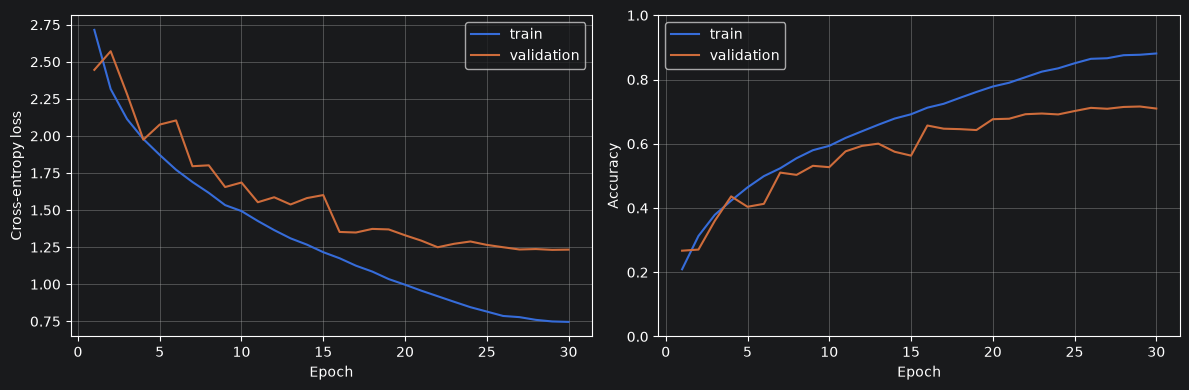

In [21]:
figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(12, 4))
loss_axis.plot(history['epoch'], history['train_loss'], label='train')
loss_axis.plot(history['epoch'], history['validation_loss'], label='validation')
loss_axis.set(xlabel='Epoch', ylabel='Cross-entropy loss')
loss_axis.grid(True)
loss_axis.legend()
accuracy_axis.plot(history['epoch'], history['train_accuracy'], label='train')
accuracy_axis.plot(
    history['epoch'], history['validation_accuracy'], label='validation'
)
accuracy_axis.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
accuracy_axis.grid(True)
accuracy_axis.legend()
figure.tight_layout()
plt.show()

In [22]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    predicted_ids = []
    predicted_indices = []
    for images, image_ids in loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        predicted_indices.extend(model(images).argmax(dim=1).cpu().tolist())
        predicted_ids.extend(image_ids.tolist())
    return predicted_ids, predicted_indices

predicted_ids, predicted_indices = predict(model, test_loader)
prediction_frame = pd.DataFrame({
    'ID': predicted_ids,
    'Label': [class_names[index] for index in predicted_indices],
})
if prediction_frame['ID'].duplicated().any():
    raise RuntimeError('Predictions contain duplicate IDs.')
if set(prediction_frame['Label']) - set(EXPECTED_CLASS_NAMES):
    raise RuntimeError('Predictions contain an invalid class label.')

submission = submission_template[['ID']].merge(
    prediction_frame, on='ID', how='left', validate='one_to_one'
)
if submission.columns.tolist() != ['ID', 'Label']:
    raise RuntimeError('Submission must contain exactly ID,Label.')
if len(submission) != EXPECTED_TEST_IMAGES or submission['Label'].isna().any():
    raise RuntimeError('Submission rows do not match the test set.')
if submission['ID'].tolist() != list(range(EXPECTED_TEST_IMAGES)):
    raise RuntimeError('Submission IDs are not ordered from 0 to 11680.')

SUBMISSION_PATH = ROOT / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
print('Submission:', SUBMISSION_PATH)
print('Rows:', len(submission))
display(submission.head())
display(submission['Label'].value_counts().sort_index())

Submission: C:\Users\nguyen\Documents\GitHub\Deep-Learning\data\submission.csv
Rows: 11681


,ID,Label
0,0,lions
1,1,birds
2,2,cows
3,3,spiders
4,4,lions


Label
birds            71
bottles         255
breads          139
butterflies     787
cakes           144
cats            214
chickens        413
cows           1204
dogs             98
ducks           212
elephants       506
fishes          385
handguns        299
horses          722
lions          4317
lipsticks       277
seals           229
snakes          156
spiders         691
vases           562
Name: count, dtype: int64